In [1]:
import numpy as np
from sklearn.linear_model import LogisticRegression

logisMD = LogisticRegression(C=0.2)

x_data = np.array([ [2,   4], [4, 11], [6,  6], [8,  5], [10, 7],
                    [12, 16], [14, 8], [16, 3], [18, 7]]) #, [10, 5]])
t_data = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1]) #, 0])

In [2]:
logisMD.fit(x_data, t_data)
print(logisMD.get_params())

{'C': 0.2, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 100, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': None, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


In [3]:
print("학습 데이터 점수: {}".format(logisMD.score(x_data, t_data)))

학습 데이터 점수: 1.0


In [4]:
test_data = np.array([[3, 17], [5, 8], [7, 21], [12,0]])
logisMD.predict(test_data)

array([0, 0, 1, 1])

In [5]:
print(logisMD.coef_, logisMD.intercept_)

[[0.52657208 0.14541484]] [-5.82025077]


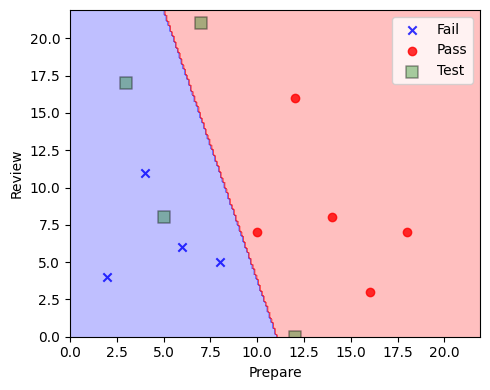

In [6]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

x1min, x1max = 0, 22
x2min, x2max = 0, 22
xx1, xx2 = np.meshgrid(np.arange(x1min, x1max, 0.1), # 0.05),
                       np.arange(x2min, x2max, 0.1))

Z = logisMD.predict(np.array([xx1.ravel(), xx2.ravel()]).T)  # meshgrid 모든 교차점에 대한 predict 값
Z = Z.reshape(xx1.shape)

failpass = ('Fail', "Pass")
markers = ('x', 'o')
colors = ('blue', 'red')
cmap = ListedColormap(colors) #[:len(np.unique(t_data))])

plt.figure(figsize=(5,4))
# print(xx1.shape, xx2.shape, Z.shape)
plt.contourf(xx1, xx2, Z, alpha=0.25, cmap=cmap)
plt.xlim(xx1.min(), xx1.max())
plt.ylim(xx2.min(), xx2.max())

for idx, cl in enumerate(np.unique(t_data)):
    plt.scatter(x=x_data[t_data ==cl, 0], y=x_data[t_data == cl, 1],
                alpha=0.8, c=colors[idx],
                marker=markers[idx], label=failpass[cl])  # edgecolor=colors[idx]) # 'b')

plt.scatter(test_data[:,0], test_data[:,1],
            c='green', edgecolor='k', alpha=0.35,
            linewidth=1.2, marker='s', s=80, label='Test')

plt.xlabel('Prepare')
plt.ylabel('Review')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [7]:
x = np.array([1, 2, 3, 4])
y = np.array([5, 6, 7])

X, Y = np.meshgrid(x, y)    # X는 y 데이터에 대응하는 x축 인덱스 나열
                            # Y는 x 데이터에 대응하는 y축 인덱스 나
print('X = \n', X)
print('Y = \n', Y)
print('X 펼침 =', X.flatten())
print('Y 펼침 =', Y.flatten())
                        # 1차원 배열 2개로 2차원 배열 ->  전치하면 -> 2쌍 입력 데이터 생성

XY_grid_data = np.stack([X.ravel(), Y.ravel()], axis=1)
# XY_grid_data = np.array([X.ravel(), Y.ravel()]).T # 는 위와 동일
print('(x,y) 쌍의 입력 형태 = \n', XY_grid_data)

Z = np.array([ c[0]*c[1] for c in np.array([X.ravel(), Y.ravel()]).T])
print("(x,y) 쌍의 연산 결과 =", Z)
Z = Z.reshape(X.shape)
print("(x,y) 쌍의 연산 결과를 격자형태로 변경\n", Z)


X = 
 [[1 2 3 4]
 [1 2 3 4]
 [1 2 3 4]]
Y = 
 [[5 5 5 5]
 [6 6 6 6]
 [7 7 7 7]]
X 펼침 = [1 2 3 4 1 2 3 4 1 2 3 4]
Y 펼침 = [5 5 5 5 6 6 6 6 7 7 7 7]
(x,y) 쌍의 입력 형태 = 
 [[1 5]
 [2 5]
 [3 5]
 [4 5]
 [1 6]
 [2 6]
 [3 6]
 [4 6]
 [1 7]
 [2 7]
 [3 7]
 [4 7]]
(x,y) 쌍의 연산 결과 = [ 5 10 15 20  6 12 18 24  7 14 21 28]
(x,y) 쌍의 연산 결과를 격자형태로 변경
 [[ 5 10 15 20]
 [ 6 12 18 24]
 [ 7 14 21 28]]
